In [ ]:

# # RNN Sentiment Classification on IMDB



import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

MAXLEN = 200        # reviews are long, so keep 200 tokens
VOCAB_SIZE = 10000  # keep the 10k most frequent words
EMBED_DIM = 64
EPOCHS = 8
BATCH = 128



In [ ]:


# %% 2. Load the dataset
URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
df = pd.read_csv(URL)  
print(df.shape)
print(df.head())
print(df["sentiment"].value_counts())  



(50000, 2)
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [4]:
# %% 3. Preprocessing
def clean(text):
    text = re.sub(r"<[^>]+>", " ", text)       # remove HTML tags like <br />
    text = re.sub(r"[^a-zA-Z']", " ", text)    # keep letters and apostrophes
    return text.lower().strip()

df["clean"] = df["review"].apply(clean)
df["label"] = (df["sentiment"] == "positive").astype(int)



In [ ]:
# Train / validation / test = 70 / 10 / 20
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2, stratify=df["label"], random_state=SEED)
X_train_txt, X_val_txt, y_train, y_val = train_test_split(
    X_train_txt, y_train, test_size=0.125, stratify=y_train, random_state=SEED)

tok = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tok.fit_on_texts(X_train_txt)  # fit on training data only (no leakage)

def to_seq(texts):
    # 'pre' padding puts real tokens next to the output step, which helps RNNs
    return pad_sequences(tok.texts_to_sequences(texts), maxlen=MAXLEN,
                         padding="pre", truncating="post")

X_train, X_val, X_test = to_seq(X_train_txt), to_seq(X_val_txt), to_seq(X_test_txt)
y_train, y_val, y_test = map(np.array, (y_train, y_val, y_test))
print("Shapes:", X_train.shape, X_val.shape, X_test.shape)





Shapes: (35000, 200) (5000, 200) (10000, 200)


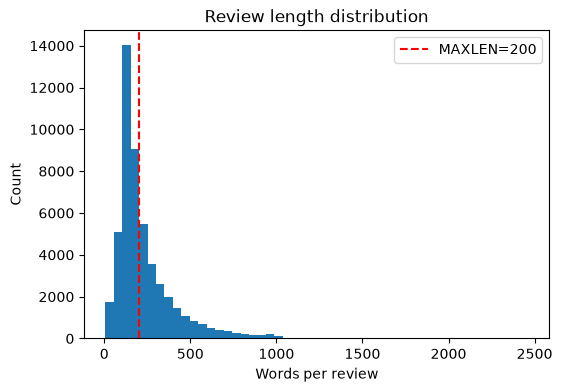

In [ ]:
# Review length distribution (snapshot for report)
lens = df["clean"].str.split().apply(len)
plt.figure(figsize=(6, 4))
plt.hist(lens, bins=50)
plt.axvline(MAXLEN, color="r", linestyle="--", label=f"MAXLEN={MAXLEN}")
plt.xlabel("Words per review"); plt.ylabel("Count"); plt.legend()
plt.title("Review length distribution")
plt.show()

In [8]:
# %% 4. Model builders
def build(kind):
    m = models.Sequential()
    m.add(layers.Embedding(VOCAB_SIZE, EMBED_DIM))
    if kind == "SimpleRNN":
        m.add(layers.SimpleRNN(64))
    elif kind == "LSTM":
        m.add(layers.LSTM(64))
    elif kind == "GRU":
        m.add(layers.GRU(64))
    elif kind == "BiLSTM":
        m.add(layers.Bidirectional(layers.LSTM(64)))
    m.add(layers.Dropout(0.3))
    m.add(layers.Dense(1, activation="sigmoid"))
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy", metrics=["accuracy"])
    return m



In [9]:
# %% 5. Train all models
results, histories, preds = {}, {}, {}
early = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                         restore_best_weights=True)

for kind in ["SimpleRNN", "LSTM", "GRU", "BiLSTM"]:
    print(f"\n===== {kind} =====")
    model = build(kind)
    model.build(input_shape=(None, MAXLEN))
    model.summary()
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=EPOCHS, batch_size=BATCH, callbacks=[early], verbose=1)
    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    histories[kind] = h.history
    preds[kind] = (model.predict(X_test, verbose=0).ravel() > 0.5).astype(int)
    results[kind] = {"params": model.count_params(),
                     "epochs_run": len(h.history["loss"]),
                     "test_loss": round(loss, 4), "test_acc": round(acc, 4)}




===== SimpleRNN =====


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 648,321 (2.47 MB)

 Trainable params: 648,321 (2.47 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 706,177 (2.69 MB)

 Trainable params: 706,177 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
274/274 ━━━━━━━━━━━━━━━━━━━━ 84s 298ms/step - accuracy: 0.7678 - loss: 0.4713 - val_accuracy: 0.8534 - val_loss: 0.3451
Epoch 2/8
274/274 ━━━━━━━━━━━━━━━━━━━━ 75s 273ms/step - accuracy: 0.8819 - loss: 0.3004 - val_accuracy: 0.8344 - val_loss: 0.4084
Epoch 3/8
274/274 ━━━━━━━━━━━━━━━━━━━━ 79s 287ms/step - accuracy: 0.8998 - loss: 0.2617 - val_accuracy: 0.8630 - val_loss: 0.3999


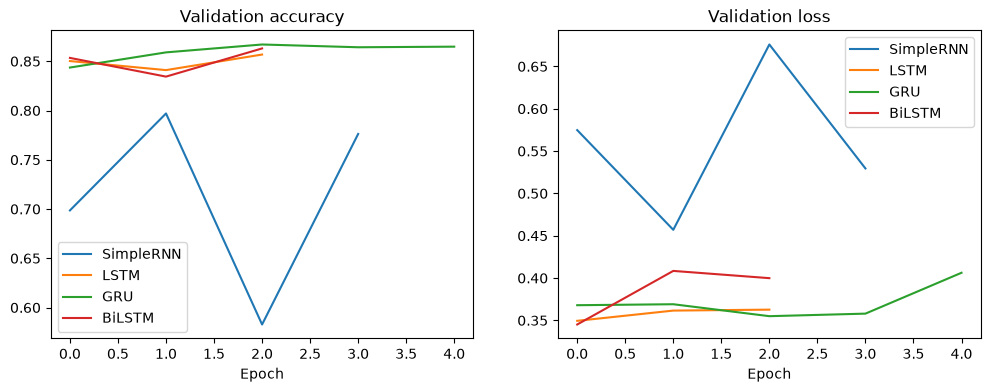

In [10]:
# %% 6. Training curves (snapshot for report)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for kind, h in histories.items():
    axes[0].plot(h["val_accuracy"], label=kind)
    axes[1].plot(h["val_loss"], label=kind)
axes[0].set_title("Validation accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].set_title("Validation loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.show()



             params  epochs_run  test_loss  test_acc  meets_82%_target
SimpleRNN  648321.0         4.0     0.4495    0.8071             False
LSTM       673089.0         3.0     0.3513    0.8468              True
GRU        665025.0         5.0     0.3486    0.8669              True
BiLSTM     706177.0         3.0     0.3407    0.8604              True


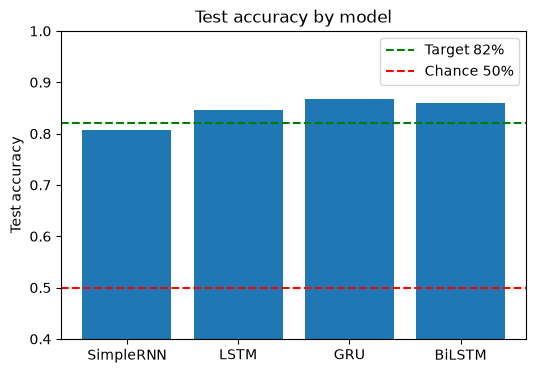

In [11]:
# %% 7. Results table and comparison against target
res_df = pd.DataFrame(results).T
res_df["meets_82%_target"] = res_df["test_acc"] >= 0.82
print(res_df)
res_df.to_csv("results_table.csv")

plt.figure(figsize=(6, 4))
plt.bar(res_df.index, res_df["test_acc"].astype(float))
plt.axhline(0.82, color="g", linestyle="--", label="Target 82%")
plt.axhline(0.50, color="r", linestyle="--", label="Chance 50%")
plt.ylim(0.4, 1.0); plt.ylabel("Test accuracy"); plt.legend()
plt.title("Test accuracy by model")
plt.show()



Best model: GRU
              precision    recall  f1-score   support

    negative       0.85      0.89      0.87      5000
    positive       0.88      0.84      0.86      5000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



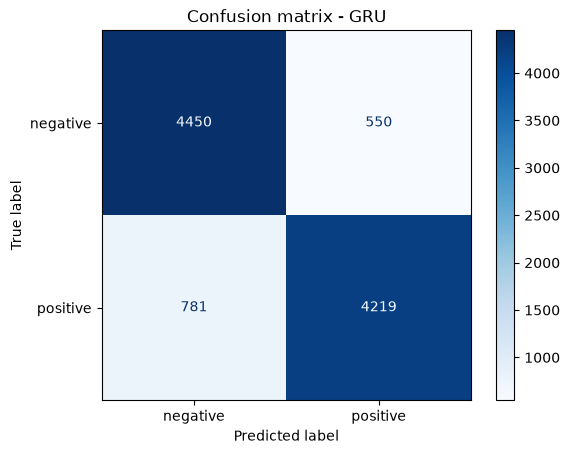

In [12]:
# %% 8. Confusion matrix and classification report for the best model
best = res_df["test_acc"].astype(float).idxmax()
print("Best model:", best)
print(classification_report(y_test, preds[best], target_names=["negative", "positive"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, preds[best]),
                       display_labels=["negative", "positive"]).plot(cmap="Blues")
plt.title(f"Confusion matrix - {best}")
plt.show()